In [1]:
import pandas as pd

gps = pd.read_csv("data/geopulse_gps_data.csv")

print("Dataset Shape:", gps.shape)
print("\nColumns:")
print(gps.columns.tolist())

print("\nFirst 5 Records:")
display(gps.head())

print("\nData Types:")
print(gps.dtypes)

print("\nUnique Devices:", gps["DeviceID"].nunique())

Dataset Shape: (100, 4)

Columns:
['DeviceID', 'Lat', 'Long', 'Timestamp']

First 5 Records:


,DeviceID,Lat,Long,Timestamp
0,D001,28.637454,77.104714,2026-11-01 00:00:00
1,D002,28.695071,77.195462,2026-11-01 01:00:00
2,D003,28.673199,77.147153,2026-11-01 02:00:00
3,D004,28.659866,77.176286,2026-11-01 03:00:00
4,D005,28.615602,77.236135,2026-11-01 04:00:00



Data Types:
DeviceID         str
Lat          float64
Long         float64
Timestamp        str
dtype: object

Unique Devices: 100


In [2]:
# Convert Timestamp to datetime
gps["Timestamp"] = pd.to_datetime(gps["Timestamp"])

# Records per device
records_per_device = gps.groupby("DeviceID").size()

print("Records per Device:")
display(records_per_device.describe())

print("\nDevices with Multiple GPS Records:")
print((records_per_device > 1).sum())

print("\nDevices with Single GPS Record:")
print((records_per_device == 1).sum())

Records per Device:


count    100.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
dtype: float64


Devices with Multiple GPS Records:
0

Devices with Single GPS Record:
100


In [3]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

NUM_DEVICES = 100
POINTS_PER_DEVICE = 100

records = []

for device_num in range(1, NUM_DEVICES + 1):

    device_id = f"D{device_num:03d}"

    # Starting location
    lat = rng.uniform(28.50, 28.80)
    lon = rng.uniform(76.90, 77.30)

    start_time = pd.Timestamp("2026-11-20 08:00:00")

    for point in range(POINTS_PER_DEVICE):

        records.append({
            "DeviceID": device_id,
            "Lat": lat,
            "Long": lon,
            "Timestamp": start_time + pd.Timedelta(minutes=5 * point)
        })

        # Small sequential movement
        lat += rng.normal(0, 0.0005)
        lon += rng.normal(0, 0.0005)

trajectories = pd.DataFrame(records)

print("Dataset Shape:", trajectories.shape)
display(trajectories.head())

Dataset Shape: (10000, 4)


,DeviceID,Lat,Long,Timestamp
0,D001,28.732187,77.075551,2026-11-20 08:00:00
1,D001,28.732562,77.076022,2026-11-20 08:05:00
2,D001,28.731587,77.075371,2026-11-20 08:10:00
3,D001,28.731650,77.075212,2026-11-20 08:15:00
4,D001,28.731642,77.074786,2026-11-20 08:20:00


In [4]:
output_path = "data/geopulse_gps_trajectories.csv"

trajectories.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: data/geopulse_gps_trajectories.csv


In [5]:
import numpy as np

def calculate_distance(lat1, lon1, lat2, lon2):
    """
    Calculate distance between two GPS coordinates in kilometers.
    """
    earth_radius = 6371.0

    lat1, lon1, lat2, lon2 = np.radians(
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return earth_radius * c

In [6]:
trajectories["Timestamp"] = pd.to_datetime(
    trajectories["Timestamp"]
)

trajectories = trajectories.sort_values(
    ["DeviceID", "Timestamp"]
).copy()

grouped = trajectories.groupby("DeviceID")

trajectories["Previous_Lat"] = grouped["Lat"].shift(1)
trajectories["Previous_Long"] = grouped["Long"].shift(1)
trajectories["Previous_Timestamp"] = grouped["Timestamp"].shift(1)

trajectories["Distance_km"] = calculate_distance(
    trajectories["Previous_Lat"],
    trajectories["Previous_Long"],
    trajectories["Lat"],
    trajectories["Long"]
)

trajectories["Time_Difference_hours"] = (
    trajectories["Timestamp"]
    - trajectories["Previous_Timestamp"]
).dt.total_seconds() / 3600

trajectories["Speed_kmh"] = (
    trajectories["Distance_km"]
    / trajectories["Time_Difference_hours"]
)

print("Movement Metrics:")
display(trajectories.head(10))

Movement Metrics:


,DeviceID,Lat,Long,Timestamp,Previous_Lat,Previous_Long,Previous_Timestamp,Distance_km,Time_Difference_hours,Speed_kmh
0,D001,28.732187,77.075551,2026-11-20 08:00:00,NaN,NaN,NaT,NaN,NaN,NaN
1,D001,28.732562,77.076022,2026-11-20 08:05:00,28.732187,77.075551,2026-11-20 08:00:00,0.061996,0.083333,0.743947
2,D001,28.731587,77.075371,2026-11-20 08:10:00,28.732562,77.076022,2026-11-20 08:05:00,0.125684,0.083333,1.508211
3,D001,28.731650,77.075212,2026-11-20 08:15:00,28.731587,77.075371,2026-11-20 08:10:00,0.016977,0.083333,0.203724
4,D001,28.731642,77.074786,2026-11-20 08:20:00,28.731650,77.075212,2026-11-20 08:15:00,0.041598,0.083333,0.499181
5,D001,28.732082,77.075175,2026-11-20 08:25:00,28.731642,77.074786,2026-11-20 08:20:00,0.061873,0.083333,0.742481
6,D001,28.732115,77.075738,2026-11-20 08:30:00,28.732082,77.075175,2026-11-20 08:25:00,0.055078,0.083333,0.660935
7,D001,28.732349,77.075309,2026-11-20 08:35:00,28.732115,77.075738,2026-11-20 08:30:00,0.049301,0.083333,0.591609
8,D001,28.732533,77.074829,2026-11-20 08:40:00,28.732349,77.075309,2026-11-20 08:35:00,0.051045,0.083333,0.612545
9,D001,28.732972,77.074804,2026-11-20 08:45:00,28.732533,77.074829,2026-11-20 08:40:00,0.048900,0.083333,0.586803


In [7]:
print("Total Distance (km):",
      trajectories["Distance_km"].sum())

print("Average Speed (km/h):",
      trajectories["Speed_kmh"].mean())

print("Maximum Speed (km/h):",
      trajectories["Speed_kmh"].max())

print("Missing Distance Values:",
      trajectories["Distance_km"].isna().sum())

Total Distance (km): 651.6657485749413
Average Speed (km/h): 0.7898978770605348
Maximum Speed (km/h): 2.6065854858556605
Missing Distance Values: 100


# Device-wise Mobility Summary

In [8]:
device_summary = (
    trajectories.groupby("DeviceID")
    .agg(
        Total_Distance_km=("Distance_km", "sum"),
        Average_Speed_kmh=("Speed_kmh", "mean"),
        Maximum_Speed_kmh=("Speed_kmh", "max"),
        Total_GPS_Records=("Lat", "count"),
        Active_Time_hours=("Time_Difference_hours", "sum")
    )
    .reset_index()
)

print("Device-wise Mobility Summary:")
display(device_summary.head(10))

Device-wise Mobility Summary:


,DeviceID,Total_Distance_km,Average_Speed_kmh,Maximum_Speed_kmh,Total_GPS_Records,Active_Time_hours
0,D001,5.792690,0.702144,2.163475,100,8.25
1,D002,6.562875,0.795500,2.056219,100,8.25
2,D003,6.629144,0.803533,2.003257,100,8.25
3,D004,6.659463,0.807208,1.838193,100,8.25
4,D005,6.214966,0.753329,2.178638,100,8.25
5,D006,6.316185,0.765598,1.949871,100,8.25
6,D007,6.877820,0.833675,1.944054,100,8.25
7,D008,6.615241,0.801847,1.819206,100,8.25
8,D009,6.545126,0.793349,1.820632,100,8.25
9,D010,6.380598,0.773406,1.952992,100,8.25


In [9]:
print("Overall Device Statistics:")

display(
    device_summary[
        [
            "Total_Distance_km",
            "Average_Speed_kmh",
            "Maximum_Speed_kmh",
            "Active_Time_hours"
        ]
    ].describe()
)

Overall Device Statistics:


,Total_Distance_km,Average_Speed_kmh,Maximum_Speed_kmh,Active_Time_hours
count,100.000000,100.000000,100.000000,100.00
mean,6.516657,0.789898,1.991332,8.25
std,0.322113,0.039044,0.232818,0.00
min,5.792690,0.702144,1.545662,8.25
25%,6.297657,0.763352,1.834730,8.25
50%,6.495203,0.787297,1.977290,8.25
75%,6.697955,0.811873,2.129631,8.25
max,7.459051,0.904127,2.606585,8.25


In [10]:
top_devices = device_summary.sort_values(
    "Total_Distance_km",
    ascending=False
).head(10)

display(top_devices)

,DeviceID,Total_Distance_km,Average_Speed_kmh,Maximum_Speed_kmh,Total_GPS_Records,Active_Time_hours
44,D045,7.459051,0.904127,2.088215,100,8.25
99,D100,7.397606,0.896680,2.086102,100,8.25
94,D095,7.392734,0.896089,2.504860,100,8.25
11,D012,7.372702,0.893661,1.909809,100,8.25
66,D067,6.921927,0.839021,1.757914,100,8.25
78,D079,6.901389,0.836532,2.176067,100,8.25
31,D032,6.891518,0.835335,1.849632,100,8.25
95,D096,6.890500,0.835212,1.928782,100,8.25
14,D015,6.882559,0.834250,1.865455,100,8.25
88,D089,6.879889,0.833926,2.238796,100,8.25


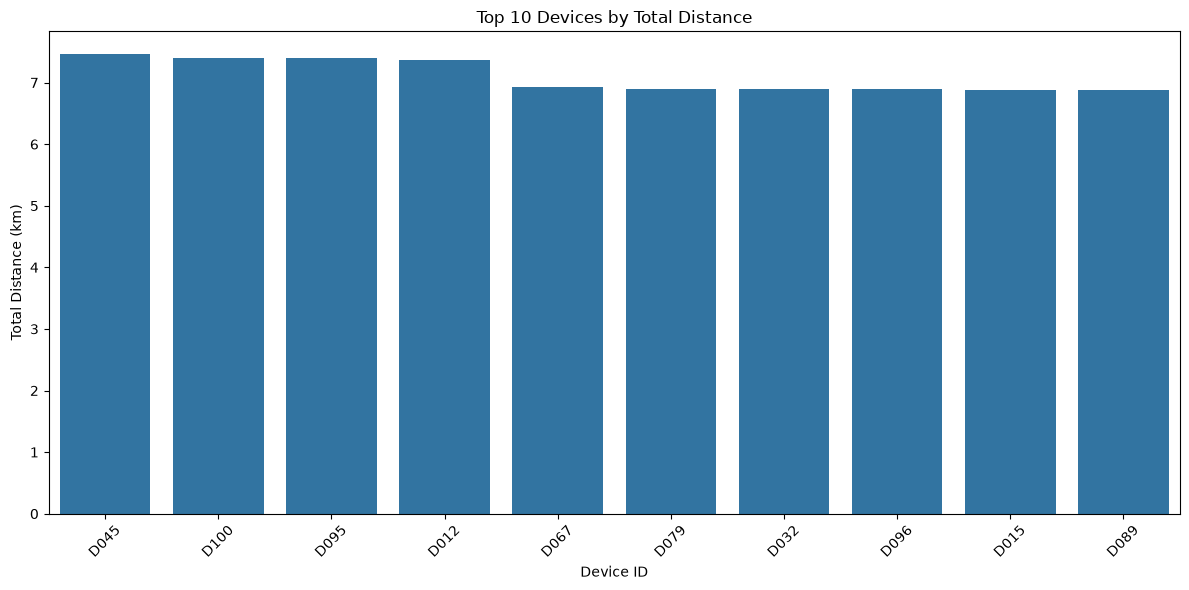

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_devices,
    x="DeviceID",
    y="Total_Distance_km"
)

plt.title("Top 10 Devices by Total Distance")
plt.xlabel("Device ID")
plt.ylabel("Total Distance (km)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

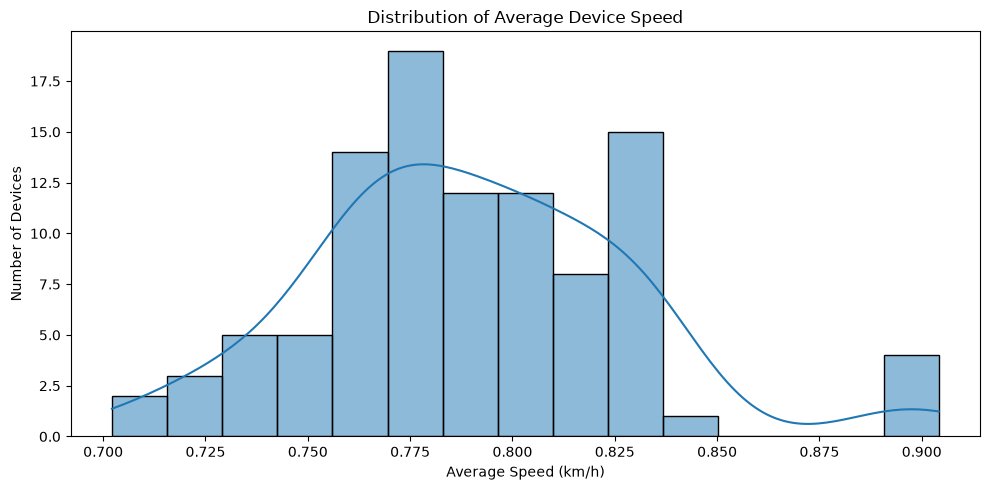

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(
    device_summary["Average_Speed_kmh"],
    bins=15,
    kde=True
)

plt.title("Distribution of Average Device Speed")
plt.xlabel("Average Speed (km/h)")
plt.ylabel("Number of Devices")
plt.tight_layout()
plt.show()

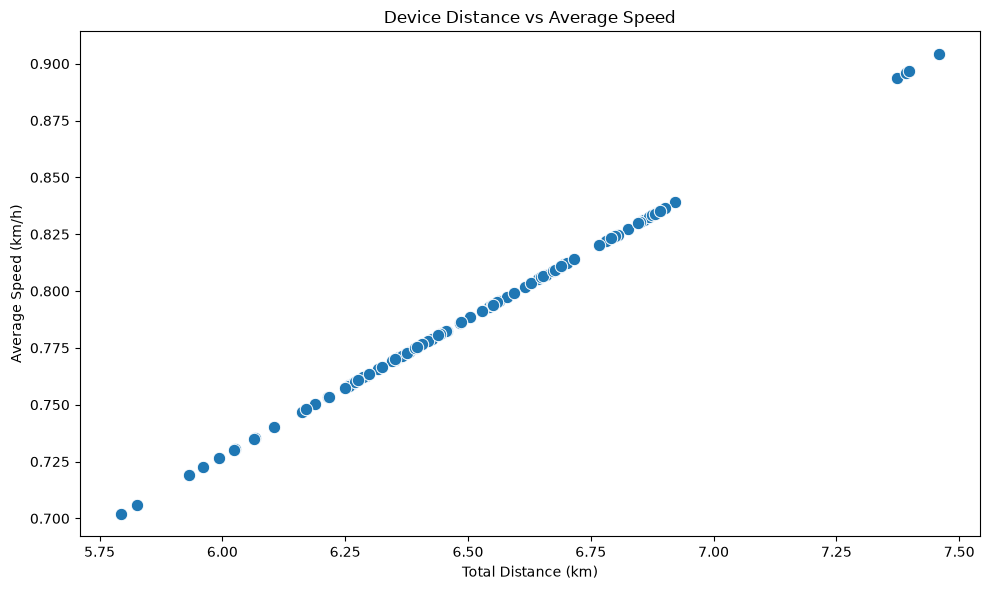

In [13]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=device_summary,
    x="Total_Distance_km",
    y="Average_Speed_kmh",
    s=80
)

plt.title("Device Distance vs Average Speed")
plt.xlabel("Total Distance (km)")
plt.ylabel("Average Speed (km/h)")
plt.tight_layout()
plt.show()

In [14]:

%%writefile src/geopulse/trajectory.py

import numpy as np
import pandas as pd


REQUIRED_COLUMNS = ["DeviceID", "Lat", "Long", "Timestamp"]


def haversine_distance_km(lat1, lon1, lat2, lon2):
    """Calculate geographic distance between two GPS points in km."""

    earth_radius = 6371.0

    lat1, lon1, lat2, lon2 = np.radians(
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return float(2 * earth_radius * np.arcsin(np.sqrt(a)))


def calculate_trajectory_metrics(data):
    """
    Calculate consecutive GPS distance, time difference,
    and movement speed for each device.
    """

    if not isinstance(data, pd.DataFrame):
        raise TypeError("Input must be a pandas DataFrame")

    missing = set(REQUIRED_COLUMNS) - set(data.columns)

    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    result = data[REQUIRED_COLUMNS].copy()

    if result.empty:
        raise ValueError("GPS dataset cannot be empty")

    if result["DeviceID"].isna().any():
        raise ValueError("DeviceID cannot contain missing values")

    for column in ["Lat", "Long"]:
        result[column] = pd.to_numeric(
            result[column], errors="raise"
        )

        if not np.isfinite(result[column]).all():
            raise ValueError(f"{column} must contain finite values")

    if not result["Lat"].between(-90, 90).all():
        raise ValueError("Latitude must be between -90 and 90")

    if not result["Long"].between(-180, 180).all():
        raise ValueError("Longitude must be between -180 and 180")

    result["Timestamp"] = pd.to_datetime(
        result["Timestamp"], errors="raise"
    )

    if result["Timestamp"].isna().any():
        raise ValueError("Timestamp cannot contain missing values")

    result = result.sort_values(
        ["DeviceID", "Timestamp"]
    ).reset_index(drop=True)

    grouped = result.groupby("DeviceID", sort=False)

    result["Previous_Lat"] = grouped["Lat"].shift(1)
    result["Previous_Long"] = grouped["Long"].shift(1)
    result["Previous_Timestamp"] = grouped["Timestamp"].shift(1)

    result["Distance_km"] = haversine_distance_km(
        result["Previous_Lat"],
        result["Previous_Long"],
        result["Lat"],
        result["Long"]
    )

    result["Time_Difference_hours"] = (
        result["Timestamp"] - result["Previous_Timestamp"]
    ).dt.total_seconds() / 3600

    valid_intervals = result["Time_Difference_hours"] > 0

    result.loc[~valid_intervals, "Distance_km"] = np.nan

    result["Speed_kmh"] = (
        result["Distance_km"]
        / result["Time_Difference_hours"]
    )

    return result


Writing src/geopulse/trajectory.py


In [16]:
import sys
from pathlib import Path

# Project root locate karo
project_root = Path.cwd()

print("Current Directory:", project_root)

# src directory Python path mein add karo
src_path = project_root / "src"

if src_path.exists():
    sys.path.insert(0, str(src_path))
    print("Source Path Added:", src_path)
else:
    print("src folder not found in current directory!")

Current Directory: C:\Users\visha\OneDrive\Desktop\GeoPulse--Hyper-Local-Retail-Mobility-Analytics
Source Path Added: C:\Users\visha\OneDrive\Desktop\GeoPulse--Hyper-Local-Retail-Mobility-Analytics\src


In [18]:
from geopulse.trajectory import (
    calculate_trajectory_metrics,
    haversine_distance_km
)

print("Trajectory module imported successfully!")

Trajectory module imported successfully!


In [20]:
import importlib
import geopulse.trajectory as trajectory

importlib.reload(trajectory)

calculate_trajectory_metrics = trajectory.calculate_trajectory_metrics
haversine_distance_km = trajectory.haversine_distance_km

print("Updated trajectory module loaded!")

Updated trajectory module loaded!


In [21]:
trajectory_results = calculate_trajectory_metrics(trajectories)

print("Result Shape:", trajectory_results.shape)

display(trajectory_results.head(10))

print("\nTotal Distance (km):",
      trajectory_results["Distance_km"].sum())

print("Average Speed (km/h):",
      trajectory_results["Speed_kmh"].mean())

print("Missing Distance Values:",
      trajectory_results["Distance_km"].isna().sum())

Result Shape: (10000, 10)


,DeviceID,Lat,Long,Timestamp,Previous_Lat,Previous_Long,Previous_Timestamp,Distance_km,Time_Difference_hours,Speed_kmh
0,D001,28.732187,77.075551,2026-11-20 08:00:00,NaN,NaN,NaT,NaN,NaN,NaN
1,D001,28.732562,77.076022,2026-11-20 08:05:00,28.732187,77.075551,2026-11-20 08:00:00,0.061996,0.083333,0.743947
2,D001,28.731587,77.075371,2026-11-20 08:10:00,28.732562,77.076022,2026-11-20 08:05:00,0.125684,0.083333,1.508211
3,D001,28.731650,77.075212,2026-11-20 08:15:00,28.731587,77.075371,2026-11-20 08:10:00,0.016977,0.083333,0.203724
4,D001,28.731642,77.074786,2026-11-20 08:20:00,28.731650,77.075212,2026-11-20 08:15:00,0.041598,0.083333,0.499181
5,D001,28.732082,77.075175,2026-11-20 08:25:00,28.731642,77.074786,2026-11-20 08:20:00,0.061873,0.083333,0.742481
6,D001,28.732115,77.075738,2026-11-20 08:30:00,28.732082,77.075175,2026-11-20 08:25:00,0.055078,0.083333,0.660935
7,D001,28.732349,77.075309,2026-11-20 08:35:00,28.732115,77.075738,2026-11-20 08:30:00,0.049301,0.083333,0.591609
8,D001,28.732533,77.074829,2026-11-20 08:40:00,28.732349,77.075309,2026-11-20 08:35:00,0.051045,0.083333,0.612545
9,D001,28.732972,77.074804,2026-11-20 08:45:00,28.732533,77.074829,2026-11-20 08:40:00,0.048900,0.083333,0.586803



Total Distance (km): 651.6657485749413
Average Speed (km/h): 0.7898978770605348
Missing Distance Values: 100


In [22]:

%%writefile tests/test_trajectory.py

import pandas as pd
import numpy as np
import pytest

from geopulse.trajectory import (
    haversine_distance_km,
    calculate_trajectory_metrics
)


def sample_data():
    return pd.DataFrame({
        "DeviceID": ["D001", "D001", "D001"],
        "Lat": [28.60, 28.61, 28.62],
        "Long": [77.10, 77.11, 77.12],
        "Timestamp": [
            "2026-11-20 08:00:00",
            "2026-11-20 08:05:00",
            "2026-11-20 08:10:00"
        ]
    })


def test_haversine_distance_scalar():
    distance = haversine_distance_km(
        28.60, 77.10, 28.61, 77.11
    )
    assert distance > 0


def test_haversine_distance_array():
    distances = haversine_distance_km(
        np.array([28.60, 28.61]),
        np.array([77.10, 77.11]),
        np.array([28.61, 28.62]),
        np.array([77.11, 77.12])
    )
    assert len(distances) == 2
    assert np.all(distances > 0)


def test_trajectory_output_shape():
    result = calculate_trajectory_metrics(sample_data())
    assert result.shape == (3, 10)


def test_first_record_has_no_previous_point():
    result = calculate_trajectory_metrics(sample_data())
    assert pd.isna(result.iloc[0]["Distance_km"])
    assert pd.isna(result.iloc[0]["Speed_kmh"])


def test_distance_is_positive():
    result = calculate_trajectory_metrics(sample_data())
    assert (result["Distance_km"].dropna() > 0).all()


def test_speed_calculation():
    result = calculate_trajectory_metrics(sample_data())
    assert (result["Speed_kmh"].dropna() > 0).all()


def test_records_are_sorted():
    data = sample_data().iloc[::-1]
    result = calculate_trajectory_metrics(data)

    assert result["Timestamp"].is_monotonic_increasing


def test_missing_columns_rejected():
    data = sample_data().drop(columns=["Lat"])

    with pytest.raises(ValueError):
        calculate_trajectory_metrics(data)


def test_invalid_latitude_rejected():
    data = sample_data()
    data.loc[0, "Lat"] = 95

    with pytest.raises(ValueError):
        calculate_trajectory_metrics(data)


def test_empty_dataframe_rejected():
    data = pd.DataFrame(columns=[
        "DeviceID", "Lat", "Long", "Timestamp"
    ])

    with pytest.raises(ValueError):
        calculate_trajectory_metrics(data)


Writing tests/test_trajectory.py
